# Model 04 — Purchase Propensity: EDA
**Dataset:** Online Shoppers Purchasing Intention  
**Target:** `Revenue` (True = purchase during the session)  
**Goal:** Understand data quality, target imbalance, feature behavior, and preprocessing needs before model training.

> Run this notebook from the project root or update `DATA_PATH` below to your local CSV path.


In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path(
    r"D:\MCA PU\Semesters\Semester 3\MCA_Projects\the-enterprise-ai-decision-intelligence-platform\ml\model_04_purchase_propensity\data\raw\online_shoppers_intention.csv"
)

print("File exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

File exists: True
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Data quality and schema

In [2]:
print("Shape:", df.shape)
print("\\nDtypes:")
display(df.dtypes.rename("dtype").to_frame())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)


Shape: (12330, 18)
\nDtypes:


,dtype
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


Missing values: 0
Duplicate rows: 125


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


## 2. Target distribution

,count,percent
Revenue,,
No purchase,10422,84.53
Purchase,1908,15.47


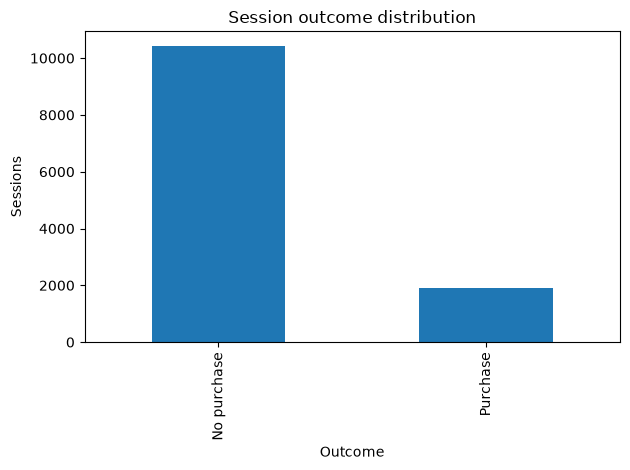

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
target_counts = df["Revenue"].value_counts().rename(index={False: "No purchase", True: "Purchase"})
display(pd.DataFrame({"count": target_counts, "percent": (target_counts / len(df) * 100).round(2)}))
target_counts.plot(kind="bar", title="Session outcome distribution", xlabel="Outcome", ylabel="Sessions")
plt.tight_layout()
plt.show()


## 3. Purchase behavior by selected features

Revenue,No purchase median,Purchase median
Administrative,0.000000,2.000000
Administrative_Duration,0.000000,52.366667
Informational,0.000000,0.000000
Informational_Duration,0.000000,0.000000
ProductRelated,16.000000,29.000000
ProductRelated_Duration,510.190000,1109.906250
BounceRates,0.004255,0.000000
ExitRates,0.028571,0.016000
PageValues,0.000000,16.758134
SpecialDay,0.000000,0.000000


,purchase_rate_percent
Month,
Nov,25.350233
Oct,20.947177
Sep,19.196429
Aug,17.551963
Jul,15.277778
Dec,12.507238
May,10.850178
June,10.069444
Mar,10.068170


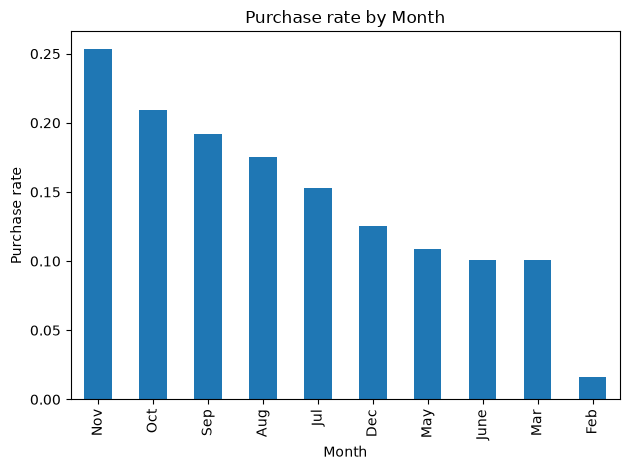

,purchase_rate_percent
VisitorType,
New_Visitor,24.911452
Other,18.823529
Returning_Visitor,13.932329


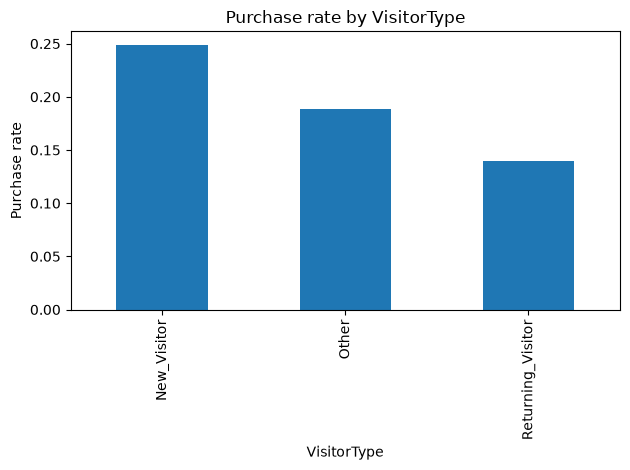

,purchase_rate_percent
Weekend,
True,17.398884
False,14.891144


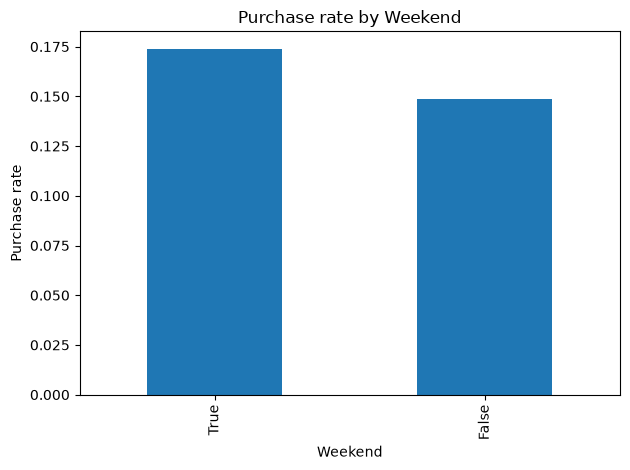

In [4]:
numeric_cols = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay"
]
display(df.groupby("Revenue")[numeric_cols].median().T.rename(columns={False:"No purchase median", True:"Purchase median"}))

for col in ["Month", "VisitorType", "Weekend"]:
    rates = df.groupby(col, observed=False)["Revenue"].mean().sort_values(ascending=False)
    display((rates * 100).rename("purchase_rate_percent").to_frame())
    rates.plot(kind="bar", title=f"Purchase rate by {col}", ylabel="Purchase rate")
    plt.tight_layout()
    plt.show()


## 4. Numeric feature distributions and correlations

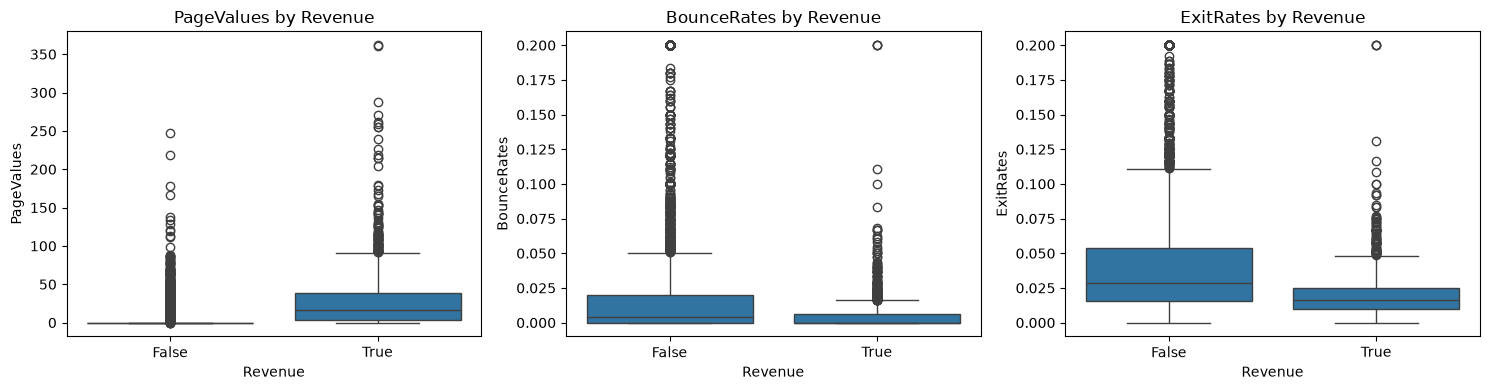

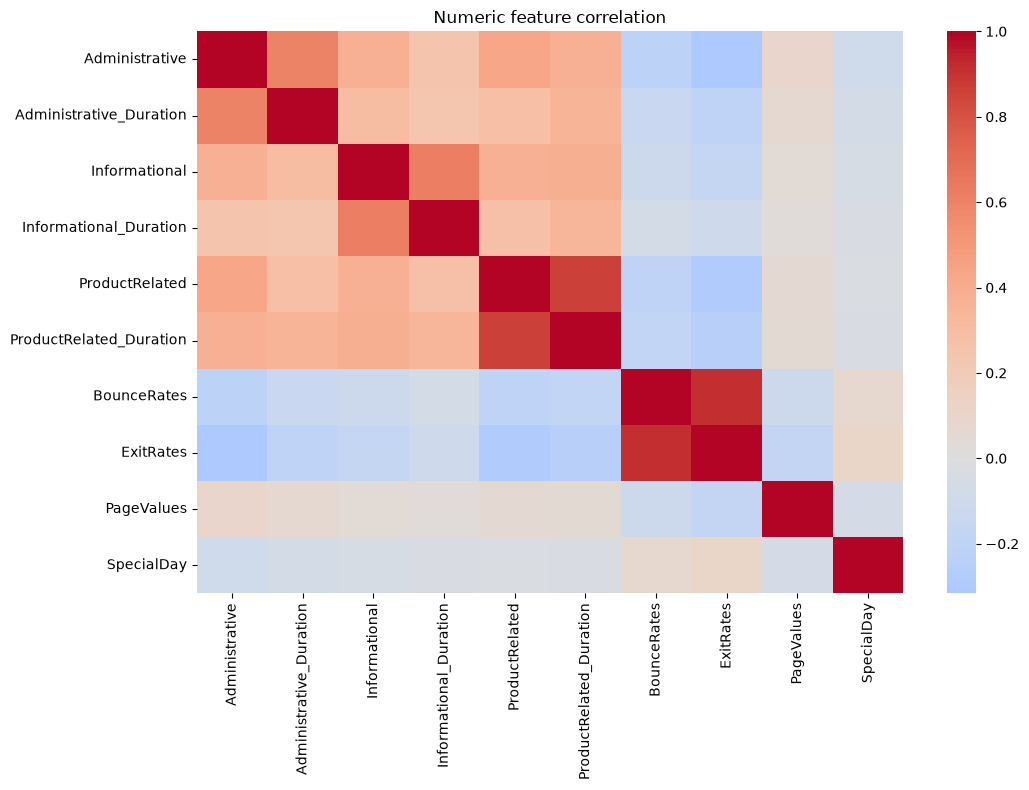

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["PageValues", "BounceRates", "ExitRates"]):
    sns.boxplot(data=df, x="Revenue", y=col, ax=ax)
    ax.set_title(f"{col} by Revenue")
plt.tight_layout()
plt.show()

corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Numeric feature correlation")
plt.tight_layout()
plt.show()


## 5. Leakage and modelling decisions
- `Revenue` is the target and must not be included in `X`.
- Investigate `PageValues` carefully: it is highly associated with the target and may reflect session conversion-related information. Keep it only if its value is available at prediction time and its definition does not encode the outcome.
- Dataset is imbalanced, so do not rely on accuracy alone. Report precision, recall, F1, ROC-AUC and PR-AUC; compare against a dummy baseline.
- The 125 exact duplicate rows found in the supplied file should be investigated before deciding whether to remove them. Do not silently drop duplicates without documenting the decision.
- Fit preprocessing only on training data using a pipeline; use a stratified train/test split.


## 6. Save a concise profiling summary

In [6]:
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Purchase sessions:", int(df["Revenue"].sum()))
print("Purchase rate (%):", round(df["Revenue"].mean() * 100, 2))
print("Non-purchase sessions:", int((~df["Revenue"]).sum()))


Rows: 12330
Columns: 18
Missing cells: 0
Exact duplicate rows: 125
Purchase sessions: 1908
Purchase rate (%): 15.47
Non-purchase sessions: 10422
